<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MOBILE DATASET
    RAM  Storage  Battery  Camera  Price_Range
0     2       32     3000       8            0
1     3       32     3500      12            0
2     4       64     4000      16            1
3     6      128     4500      32            1
4     8      128     5000      48            2
5    12      256     5500      64            3
6     2       16     2800       8            0
7     4       64     4000      16            1
8     6      128     4500      32            1
9     8      256     5000      48            2
10   12      256     6000      64            3
11    3       32     3500      12            0
12    4       64     4200      16            1
13    8      128     5000      48            2
14   12      256     5500      64            3
15    6      128     4800      32            2
16    2       16     2500       5            0
17    8      256     5200      50            3
18   12      512     6000     108            3
19    4       64     4000      16            

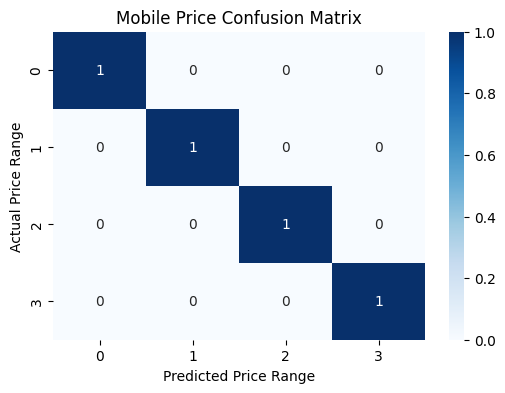

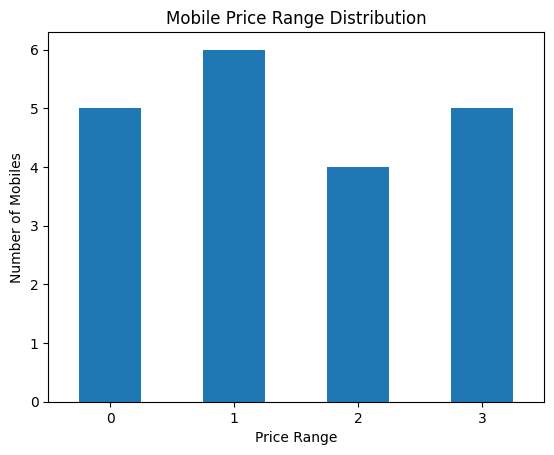

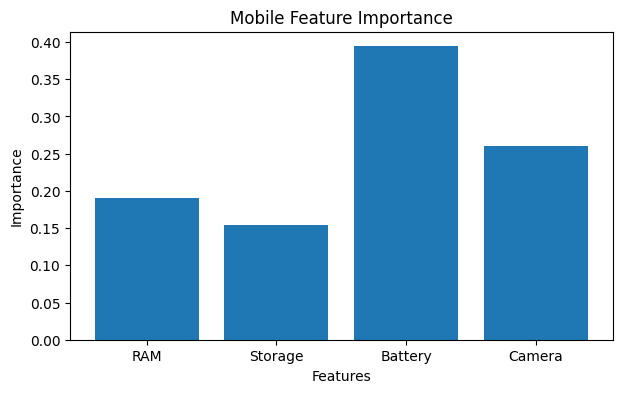

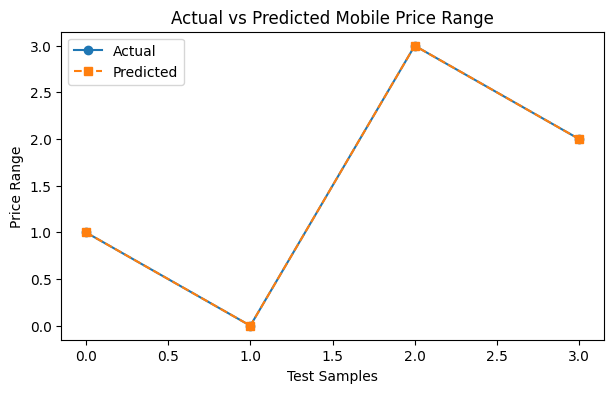


NEW MOBILE DETAILS
   RAM  Storage  Battery  Camera
0    8      128     5000      48

Predicted Price Range: High Price


In [1]:
# EXPERIMENT 17: MOBILE PRICE PREDICTION

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Create mobile dataset
data = {
    'RAM': [2, 3, 4, 6, 8, 12, 2, 4, 6, 8,
            12, 3, 4, 8, 12, 6, 2, 8, 12, 4],

    'Storage': [32, 32, 64, 128, 128, 256, 16, 64, 128, 256,
                256, 32, 64, 128, 256, 128, 16, 256, 512, 64],

    'Battery': [3000, 3500, 4000, 4500, 5000, 5500, 2800,
                4000, 4500, 5000, 6000, 3500, 4200, 5000,
                5500, 4800, 2500, 5200, 6000, 4000],

    'Camera': [8, 12, 16, 32, 48, 64, 8, 16, 32, 48,
               64, 12, 16, 48, 64, 32, 5, 50, 108, 16],

    'Price_Range': [0, 0, 1, 1, 2, 3, 0, 1, 1, 2,
                    3, 0, 1, 2, 3, 2, 0, 3, 3, 1]
}

df = pd.DataFrame(data)

print("MOBILE DATASET")
print(df)

# Step 3: Separate input and output
X = df[['RAM', 'Storage', 'Battery', 'Camera']]
y = df['Price_Range']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 5: Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel Trained Successfully!")

# Step 6: Predict mobile price range
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Price Range': y_test.values,
    'Predicted Price Range': y_pred
})

print("\nMOBILE PRICE PREDICTION")
print(results)

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

# Step 8: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Mobile Price Confusion Matrix")
plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")
plt.show()

# Step 9: Price Range Distribution
df['Price_Range'].value_counts().sort_index().plot(kind='bar')

plt.title("Mobile Price Range Distribution")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobiles")
plt.xticks(rotation=0)
plt.show()

# Step 10: Feature Importance
plt.figure(figsize=(7, 4))

plt.bar(X.columns, model.feature_importances_)

plt.title("Mobile Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

# Step 11: Actual vs Predicted Graph
plt.figure(figsize=(7, 4))

plt.plot(y_test.values, 'o-', label='Actual')
plt.plot(y_pred, 's--', label='Predicted')

plt.title("Actual vs Predicted Mobile Price Range")
plt.xlabel("Test Samples")
plt.ylabel("Price Range")
plt.legend()
plt.show()

# Step 12: Predict New Mobile
new_mobile = pd.DataFrame({
    'RAM': [8],
    'Storage': [128],
    'Battery': [5000],
    'Camera': [48]
})

prediction = model.predict(new_mobile)

price_labels = {
    0: "Low Price",
    1: "Medium Price",
    2: "High Price",
    3: "Very High Price"
}

print("\nNEW MOBILE DETAILS")
print(new_mobile)

print("\nPredicted Price Range:",
      price_labels[prediction[0]])